In [1]:
# Librerías principales
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import datetime
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
from IPython.display import display


In [2]:
# Cargar datos de la encuesta y quitar la marca de tiempo
df = pd.read_excel("Encuesta sobre uso de dispositivos y calidad del sueño (Respuestas).xlsx")
df = df.drop(columns=["Marca temporal"])


### Análisis exploratorio


In [3]:
df.columns

Index(['Sexo', 'Edad Cumplida (Años ) ',
       '¿Que semestre cursa actualmente? (Determinado por la materia del semestre más bajo, este inscrita o no)',
       '¿Qué dispositivo utiliza principalmente antes de dormir? \n(En un período de 3 horas o menos antes de conciliar el sueño)',
       '¿Cuanto tiempo suele dedicar al uso de pantallas antes de dormir? \n',
       '¿Cuál es la actividad principal que realiza en el dispositivo? ',
       '¿A que hora suele levantarse en días de semana? ( lunes a viernes)',
       '¿A que hora suele acostarse en días de semana? ( lunes a viernes)',
       '¿A que hora suele levantarse en fines de semana?',
       '¿A que hora suele acostarse en fines de semana?',
       '¿Cuántas veces suele despertarse involuntariamente durante la noche?',
       'Al despertar por las mañanas, usted habitualmente siente'],
      dtype='str')

In [4]:
# Renombrar columnas a Pregunta 1...12 para trabajar más cómodo
df2 = df.copy()
df2.columns = [f"Pregunta {i}" for i in range(1, 13)]
df2.info()


<class 'pandas.DataFrame'>
RangeIndex: 28 entries, 0 to 27
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Pregunta 1   28 non-null     str   
 1   Pregunta 2   28 non-null     object
 2   Pregunta 3   28 non-null     int64 
 3   Pregunta 4   28 non-null     str   
 4   Pregunta 5   28 non-null     str   
 5   Pregunta 6   28 non-null     str   
 6   Pregunta 7   28 non-null     object
 7   Pregunta 8   28 non-null     object
 8   Pregunta 9   28 non-null     object
 9   Pregunta 10  28 non-null     object
 10  Pregunta 11  28 non-null     str   
 11  Pregunta 12  28 non-null     str   
dtypes: int64(1), object(5), str(6)
memory usage: 2.8+ KB


In [5]:
df2.head(3)

,Pregunta 1,Pregunta 2,Pregunta 3,Pregunta 4,Pregunta 5,Pregunta 6,Pregunta 7,Pregunta 8,Pregunta 9,Pregunta 10,Pregunta 11,Pregunta 12
0,Masculino,21,5,Teléfono Inteligente,De 60 a 119 minutos,Redes sociales / Mensajería,06:00:00,22:00:00,10:30:00,23:00:00,Dos veces,Energía suficiente para toda la jornada académ...
1,Masculino,20,4,Teléfono Inteligente,180 minutos o más,Redes sociales / Mensajería,09:00:00,09:00:00,09:00:00,10:00:00,Una vez,Cansancio leve que desaparece tras la primera ...
2,Masculino,22,4,Teléfono Inteligente,De 30 a 59 minutos,Redes sociales / Mensajería,05:30:00,12:00:00,09:00:00,12:00:00,Una vez,Cansancio leve que desaparece tras la primera ...


In [6]:
# Convertir horas a formato decimal (ej: 6:30 -> 6.5)
def to_hours(val):
    if hasattr(val, "hour"):
        return val.hour + val.minute / 60.0
    s = str(val).split(":")
    return int(s[0]) + int(s[1]) / 60.0

# Ajustar horas de la noche escritas en formato 12h (ej: 10:00 -> 22:00, 12:00 -> 00:00)
def fix_bedtime(h):
    h_arr = np.asarray(h, dtype=np.float64)
    return np.where(
        (h_arr >= 8.0) & (h_arr < 12.0),
        h_arr + 12.0,
        np.where((h_arr >= 12.0) & (h_arr < 13.0), h_arr - 12.0, h_arr)
    )

df2["lev_sem_h"] = df2["Pregunta 7"].apply(to_hours).to_numpy(dtype=np.float64)
df2["acost_sem_h"] = fix_bedtime(df2["Pregunta 8"].apply(to_hours))
df2["lev_fin_h"] = df2["Pregunta 9"].apply(to_hours).to_numpy(dtype=np.float64)
df2["acost_fin_h"] = fix_bedtime(df2["Pregunta 10"].apply(to_hours))

df2.info()
df2.head()


<class 'pandas.DataFrame'>
RangeIndex: 28 entries, 0 to 27
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Pregunta 1   28 non-null     str    
 1   Pregunta 2   28 non-null     object 
 2   Pregunta 3   28 non-null     int64  
 3   Pregunta 4   28 non-null     str    
 4   Pregunta 5   28 non-null     str    
 5   Pregunta 6   28 non-null     str    
 6   Pregunta 7   28 non-null     object 
 7   Pregunta 8   28 non-null     object 
 8   Pregunta 9   28 non-null     object 
 9   Pregunta 10  28 non-null     object 
 10  Pregunta 11  28 non-null     str    
 11  Pregunta 12  28 non-null     str    
 12  lev_sem_h    28 non-null     float64
 13  acost_sem_h  28 non-null     float64
 14  lev_fin_h    28 non-null     float64
 15  acost_fin_h  28 non-null     float64
dtypes: float64(4), int64(1), object(5), str(6)
memory usage: 3.6+ KB


,Pregunta 1,Pregunta 2,Pregunta 3,Pregunta 4,Pregunta 5,Pregunta 6,Pregunta 7,Pregunta 8,Pregunta 9,Pregunta 10,Pregunta 11,Pregunta 12,lev_sem_h,acost_sem_h,lev_fin_h,acost_fin_h
0,Masculino,21,5,Teléfono Inteligente,De 60 a 119 minutos,Redes sociales / Mensajería,06:00:00,22:00:00,10:30:00,23:00:00,Dos veces,Energía suficiente para toda la jornada académ...,6.0,22.0,10.5,23.0
1,Masculino,20,4,Teléfono Inteligente,180 minutos o más,Redes sociales / Mensajería,09:00:00,09:00:00,09:00:00,10:00:00,Una vez,Cansancio leve que desaparece tras la primera ...,9.0,21.0,9.0,22.0
2,Masculino,22,4,Teléfono Inteligente,De 30 a 59 minutos,Redes sociales / Mensajería,05:30:00,12:00:00,09:00:00,12:00:00,Una vez,Cansancio leve que desaparece tras la primera ...,5.5,0.0,9.0,0.0
3,Femenino,24,7,Teléfono Inteligente,De 60 a 119 minutos,Redes sociales / Mensajería,05:00:00,22:00:00,07:30:00,23:00:00,Dos veces,Cansancio leve que desaparece tras la primera ...,5.0,22.0,7.5,23.0
4,Masculino,30,8,Teléfono Inteligente,De 60 a 119 minutos,Redes sociales / Mensajería,06:00:00,12:00:00,07:00:00,12:00:00,Ninguna,Cansancio leve que desaparece tras la primera ...,6.0,0.0,7.0,0.0


In [7]:
# Limpiar edad extrayendo solo el número (quita la palabra "años")
df2["Pregunta 2"] = pd.to_numeric(
    df2["Pregunta 2"].astype(str).str.extract(r"(\d+)")[0],
    errors="coerce"
).astype("int64")

df2.info()


<class 'pandas.DataFrame'>
RangeIndex: 28 entries, 0 to 27
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Pregunta 1   28 non-null     str    
 1   Pregunta 2   28 non-null     int64  
 2   Pregunta 3   28 non-null     int64  
 3   Pregunta 4   28 non-null     str    
 4   Pregunta 5   28 non-null     str    
 5   Pregunta 6   28 non-null     str    
 6   Pregunta 7   28 non-null     object 
 7   Pregunta 8   28 non-null     object 
 8   Pregunta 9   28 non-null     object 
 9   Pregunta 10  28 non-null     object 
 10  Pregunta 11  28 non-null     str    
 11  Pregunta 12  28 non-null     str    
 12  lev_sem_h    28 non-null     float64
 13  acost_sem_h  28 non-null     float64
 14  lev_fin_h    28 non-null     float64
 15  acost_fin_h  28 non-null     float64
dtypes: float64(4), int64(2), object(4), str(6)
memory usage: 3.6+ KB


In [8]:
# Revisar valores únicos en columnas clave
for col in ["Pregunta 2", "Pregunta 5", "Pregunta 7", "Pregunta 8", "Pregunta 11", "Pregunta 12"]:
    print(f"--- {col} ---")
    print(df2[col].unique()[:5])


--- Pregunta 2 ---
[21 20 22 24 30]
--- Pregunta 5 ---
<StringArray>
['De 60 a 119 minutos',   '180 minutos o más',  'De 30 a 59 minutos',
   '120 a 179 minutos', 'Menos de 30 minutos']
Length: 5, dtype: str
--- Pregunta 7 ---
[datetime.time(6, 0) datetime.time(9, 0) datetime.time(5, 30)
 datetime.time(5, 0) datetime.time(7, 0)]
--- Pregunta 8 ---
[datetime.time(22, 0) datetime.time(9, 0) datetime.time(12, 0)
 datetime.time(22, 30) datetime.time(11, 0)]
--- Pregunta 11 ---
<StringArray>
['Dos veces', 'Una vez', 'Ninguna', '3 o más veces']
Length: 4, dtype: str
--- Pregunta 12 ---
<StringArray>
[            'Energía suficiente para toda la jornada académica.',
            'Cansancio leve que desaparece tras la primera hora.',
 'Somnolencia persistente que afecta su concentración en clases.']
Length: 3, dtype: str


In [9]:
for col in ['Pregunta 4', 'Pregunta 5', 'Pregunta 11', 'Pregunta 12']:
    print(f"--- {col} ---")
    print(df2[col].unique())

--- Pregunta 4 ---
<StringArray>
[     'Teléfono Inteligente',      'Televisor / Smart TV',
 'Computadora de escritorio',      'Computadora portátil']
Length: 4, dtype: str
--- Pregunta 5 ---
<StringArray>
['De 60 a 119 minutos',   '180 minutos o más',  'De 30 a 59 minutos',
   '120 a 179 minutos', 'Menos de 30 minutos']
Length: 5, dtype: str
--- Pregunta 11 ---
<StringArray>
['Dos veces', 'Una vez', 'Ninguna', '3 o más veces']
Length: 4, dtype: str
--- Pregunta 12 ---
<StringArray>
[            'Energía suficiente para toda la jornada académica.',
            'Cansancio leve que desaparece tras la primera hora.',
 'Somnolencia persistente que afecta su concentración en clases.']
Length: 3, dtype: str


### Procesamiento de variables y horas de sueño


In [10]:
# Calcular horas de sueño considerando el cambio de día a medianoche
sueno_sem_calc = np.where(
    df2["acost_sem_h"] >= 14.0,
    (24.0 - df2["acost_sem_h"]) + df2["lev_sem_h"],
    df2["lev_sem_h"] - df2["acost_sem_h"]
)
sueno_fin_calc = np.where(
    df2["acost_fin_h"] >= 14.0,
    (24.0 - df2["acost_fin_h"]) + df2["lev_fin_h"],
    df2["lev_fin_h"] - df2["acost_fin_h"]
)

# Caso especial: el encuestado 2 puso 9:00 tanto al acostarse como al levantarse.
# Como la fórmula no puede adivinar su hora real, le asignamos el mínimo válido del grupo (4 horas).
hora_acost_raw = df2["Pregunta 8"].apply(to_hours).to_numpy(dtype=np.float64)
mismo_horario = (hora_acost_raw == df2["lev_sem_h"]) | (sueno_sem_calc <= 0)
minimo_valido = np.sort(sueno_sem_calc[~mismo_horario])[0]  # 4.0 horas

df2["Sueno_Semana"] = sueno_sem_calc.copy()
df2.loc[mismo_horario, "Sueno_Semana"] = minimo_valido
df2["Sueno_Finde"] = sueno_fin_calc

# Promedio semanal ponderado (5 días de clase y 2 de fin de semana) y horas recuperadas
df2["Sueno_Ponderado"] = (5.0 * df2["Sueno_Semana"] + 2.0 * df2["Sueno_Finde"]) / 7.0
df2["Compensacion_Finde"] = df2["Sueno_Finde"] - df2["Sueno_Semana"]

display(df2[["Sueno_Semana", "Sueno_Finde", "Sueno_Ponderado", "Compensacion_Finde"]].head())


,Sueno_Semana,Sueno_Finde,Sueno_Ponderado,Compensacion_Finde
0,8.0,11.5,9.000000,3.5
1,4.0,11.0,6.000000,7.0
2,5.5,9.0,6.500000,3.5
3,7.0,8.5,7.428571,1.5
4,6.0,7.0,6.285714,1.0


In [11]:
# Convertir tiempo de pantalla a minutos y sensación al despertar a escala 1-3
df2["Pregunta 5"] = df2["Pregunta 5"].str.strip()
df2["Pregunta 12"] = df2["Pregunta 12"].str.strip()

mapa_minutos = {
    "Menos de 30 minutos": 15.0,
    "De 30 a 59 minutos": 44.5,
    "De 60 a 119 minutos": 89.5,
    "120 a 179 minutos": 149.5,
    "180 minutos o más": 195.0
}
mapa_tramos = {
    "Menos de 30 minutos": "< 60 min",
    "De 30 a 59 minutos": "< 60 min",
    "De 60 a 119 minutos": "60 a 119 min",
    "120 a 179 minutos": "120 min o más",
    "180 minutos o más": "120 min o más"
}
etiquetas_tramos = ["< 60 min", "60 a 119 min", "120 min o más"]

df2["Minutos_Pantalla"] = df2["Pregunta 5"].map(mapa_minutos)
df2["Tramo_Pantalla"] = pd.Categorical(
    df2["Pregunta 5"].map(mapa_tramos),
    categories=etiquetas_tramos,
    ordered=True
)

# 1: Somnolencia en clases, 2: Cansancio leve, 3: Energía suficiente
mapa_calidad = {
    "Somnolencia persistente que afecta su concentración en clases.": 1,
    "Cansancio leve que desaparece tras la primera hora.": 2,
    "Energía suficiente para toda la jornada académica.": 3
}
df2["Calidad_Sueño"] = df2["Pregunta 12"].map(mapa_calidad)


In [12]:
# Agrupar semestres por ciclo y marcar quién duerme menos de 7 horas en semana
df2["Ciclo_Semestre"] = pd.cut(
    df2["Pregunta 3"],
    bins=[0, 3, 6, 10],
    labels=["Básico (1-3)", "Intermedio (4-6)", "Finales (7-10)"]
)

df2["Condicion_Descanso"] = np.where(df2["Sueno_Semana"] < 7.0, "Déficit (< 7h)", "Óptimo (>= 7h)")
df2.head()


,Pregunta 1,Pregunta 2,Pregunta 3,Pregunta 4,Pregunta 5,Pregunta 6,Pregunta 7,Pregunta 8,Pregunta 9,Pregunta 10,...,acost_fin_h,Sueno_Semana,Sueno_Finde,Sueno_Ponderado,Compensacion_Finde,Minutos_Pantalla,Tramo_Pantalla,Calidad_Sueño,Ciclo_Semestre,Condicion_Descanso
0,Masculino,21,5,Teléfono Inteligente,De 60 a 119 minutos,Redes sociales / Mensajería,06:00:00,22:00:00,10:30:00,23:00:00,...,23.0,8.0,11.5,9.000000,3.5,89.5,60 a 119 min,3,Intermedio (4-6),Óptimo (>= 7h)
1,Masculino,20,4,Teléfono Inteligente,180 minutos o más,Redes sociales / Mensajería,09:00:00,09:00:00,09:00:00,10:00:00,...,22.0,4.0,11.0,6.000000,7.0,195.0,120 min o más,2,Intermedio (4-6),Déficit (< 7h)
2,Masculino,22,4,Teléfono Inteligente,De 30 a 59 minutos,Redes sociales / Mensajería,05:30:00,12:00:00,09:00:00,12:00:00,...,0.0,5.5,9.0,6.500000,3.5,44.5,< 60 min,2,Intermedio (4-6),Déficit (< 7h)
3,Femenino,24,7,Teléfono Inteligente,De 60 a 119 minutos,Redes sociales / Mensajería,05:00:00,22:00:00,07:30:00,23:00:00,...,23.0,7.0,8.5,7.428571,1.5,89.5,60 a 119 min,2,Finales (7-10),Óptimo (>= 7h)
4,Masculino,30,8,Teléfono Inteligente,De 60 a 119 minutos,Redes sociales / Mensajería,06:00:00,12:00:00,07:00:00,12:00:00,...,0.0,6.0,7.0,6.285714,1.0,89.5,60 a 119 min,2,Finales (7-10),Déficit (< 7h)


### Tabulaciones de frecuencia


In [13]:
# Tablas de frecuencia con conteo y porcentaje
def crear_tabla_frecuencia(serie):
    f_abs = serie.value_counts(sort=False)
    f_rel = (serie.value_counts(normalize=True, sort=False) * 100).round(2)
    tabla = pd.DataFrame({
        "Frecuencia (ni)": f_abs,
        "Porcentaje (%)": f_rel
    })
    return tabla

print("Distribución según Dispositivo Principal:")
display(crear_tabla_frecuencia(df2["Pregunta 4"]))

print()
print("Distribución según Exposición a Pantallas:")
display(crear_tabla_frecuencia(df2["Tramo_Pantalla"]))

print()
print("Distribución según descanso entre Semana:")
display(crear_tabla_frecuencia(df2["Condicion_Descanso"]))


Distribución según Dispositivo Principal:


,Frecuencia (ni),Porcentaje (%)
Pregunta 4,,
Teléfono Inteligente,19,67.86
Televisor / Smart TV,4,14.29
Computadora de escritorio,3,10.71
Computadora portátil,2,7.14



Distribución según Exposición a Pantallas:


,Frecuencia (ni),Porcentaje (%)
Tramo_Pantalla,,
< 60 min,12,42.86
60 a 119 min,10,35.71
120 min o más,6,21.43



Distribución según descanso entre Semana:


,Frecuencia (ni),Porcentaje (%)
Condicion_Descanso,,
Óptimo (>= 7h),13,46.43
Déficit (< 7h),15,53.57


In [14]:
# Resumen de estadísticas descriptivas (media, mediana, dispersión)
cols_numericas = ["Pregunta 2", "Minutos_Pantalla", "Sueno_Semana", "Sueno_Finde", "Sueno_Ponderado", "Compensacion_Finde"]
cols_str = ["Edad (años)", "Tiempo de uso (min)", "Sueño Semana (h)", "Sueño Finde (h)", "Sueño Ponderado (h)", "Compensación Finde (h)"]

resumen = pd.DataFrame({
    "Media": df2[cols_numericas].mean().values,
    "Mediana": df2[cols_numericas].median().values,
    "Desv. Estándar (s)": df2[cols_numericas].std(ddof=1).values,
    "Mínimo": df2[cols_numericas].min().values,
    "Q1 (25%)": df2[cols_numericas].quantile(0.25).values,
    "Q3 (75%)": df2[cols_numericas].quantile(0.75).values,
    "Máximo": df2[cols_numericas].max().values
}, index=cols_str).round(2)

resumen["RIC"] = (resumen["Q3 (75%)"] - resumen["Q1 (25%)"]).round(2)
resumen["CV (%)"] = ((resumen["Desv. Estándar (s)"] / resumen["Media"]) * 100).round(2)
display(resumen)


,Media,Mediana,Desv. Estándar (s),Mínimo,Q1 (25%),Q3 (75%),Máximo,RIC,CV (%)
Edad (años),23.32,21.00,6.78,18.00,19.75,24.50,51.00,4.75,29.07
Tiempo de uso (min),82.68,89.50,56.05,15.00,44.50,89.50,195.00,45.00,67.79
Sueño Semana (h),6.67,6.67,1.51,4.00,5.88,7.62,9.33,1.74,22.64
Sueño Finde (h),8.93,9.00,1.58,6.50,8.00,10.00,13.00,2.00,17.69
Sueño Ponderado (h),7.32,7.14,1.18,5.18,6.45,8.16,9.57,1.71,16.12
Compensación Finde (h),2.26,2.00,2.16,-1.00,1.00,3.31,8.50,2.31,95.58


### Gráficos


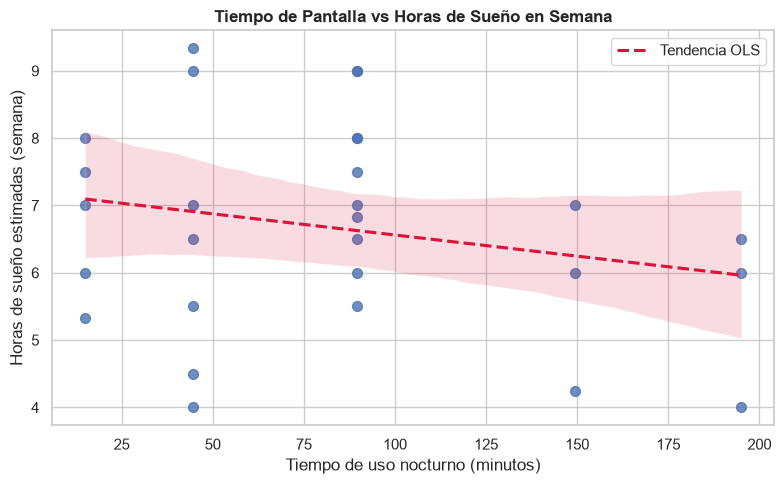

In [15]:
sns.set_theme(style="whitegrid")

# Gráfico 1: Tiempo de pantalla vs horas de sueño en semana
plt.figure(figsize=(8, 5))
sns.regplot(
    data=df2, x="Minutos_Pantalla", y="Sueno_Semana",
    scatter_kws={"s": 50, "alpha": 0.8},
    line_kws={"color": "crimson", "linestyle": "--", "label": "Tendencia OLS"}
)
plt.title("Tiempo de Pantalla vs Horas de Sueño en Semana", fontweight="bold")
plt.xlabel("Tiempo de uso nocturno (minutos)")
plt.ylabel("Horas de sueño estimadas (semana)")
plt.legend()
plt.tight_layout()
plt.show()


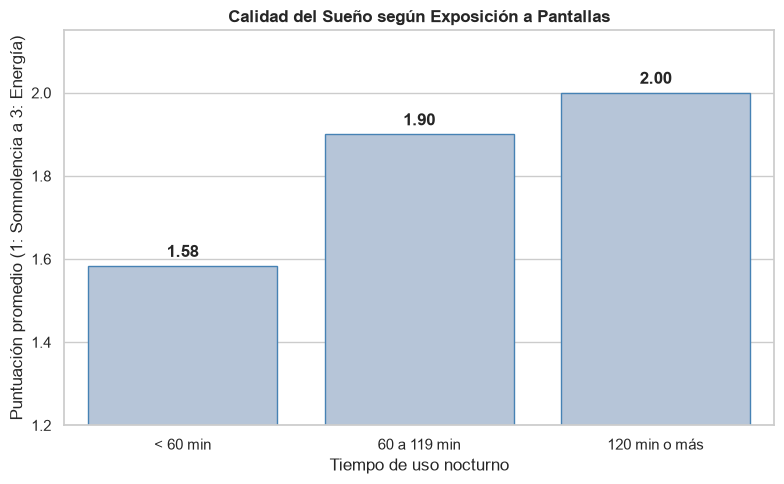

In [16]:
# Gráfico 2: Calidad del sueño según tiempo de pantalla (eje Y ajustado para ver la diferencia)
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=df2, x="Tramo_Pantalla", y="Calidad_Sueño",
    color="lightsteelblue", edgecolor="steelblue", errorbar=None
)
plt.title("Calidad del Sueño según Exposición a Pantallas", fontweight="bold")
plt.xlabel("Tiempo de uso nocturno")
plt.ylabel("Puntuación promedio (1: Somnolencia a 3: Energía)")
plt.ylim(1.2, 2.15)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha="center", va="bottom", xytext=(0, 4), textcoords="offset points", fontweight="bold")
plt.tight_layout()
plt.show()


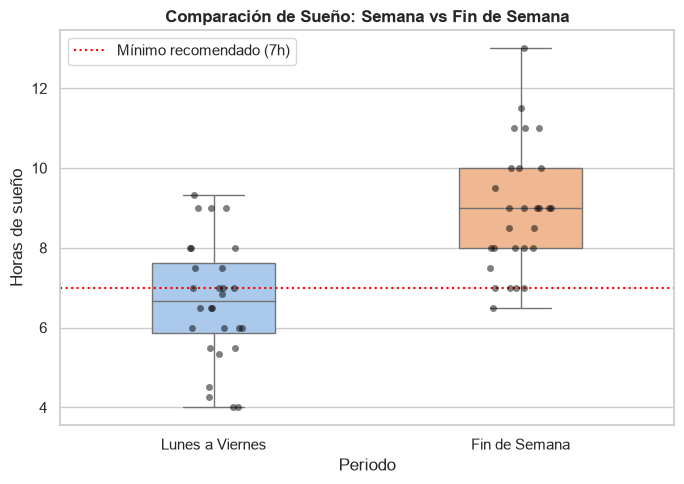

In [17]:
# Gráfico 3: Horas de sueño en semana vs fin de semana
plt.figure(figsize=(7, 5))
datos_cajas = pd.melt(
    df2[["Sueno_Semana", "Sueno_Finde"]].rename(columns={"Sueno_Semana": "Lunes a Viernes", "Sueno_Finde": "Fin de Semana"}),
    var_name="Periodo", value_name="Horas"
)
sns.boxplot(data=datos_cajas, x="Periodo", y="Horas", hue="Periodo", width=0.4, palette="pastel", legend=False)
sns.stripplot(data=datos_cajas, x="Periodo", y="Horas", color="black", alpha=0.5, jitter=0.1)
plt.axhline(7, color="red", linestyle=":", label="Mínimo recomendado (7h)")
plt.title("Comparación de Sueño: Semana vs Fin de Semana", fontweight="bold")
plt.ylabel("Horas de sueño")
plt.legend()
plt.tight_layout()
plt.show()


In [18]:
# Pruebas estadísticas
# 1. Normalidad de las horas de sueño (Shapiro-Wilk)
stat_sw, p_sw = stats.shapiro(df2["Sueno_Semana"].dropna())
print(f"Shapiro-Wilk (Sueño Semana): W = {stat_sw:.4f}, p-valor = {p_sw:.4f}")

# 2. Intervalo de confianza al 95% para la media de sueño en semana
s_sem = df2["Sueno_Semana"].dropna()
ic_95 = stats.t.interval(0.95, df=len(s_sem)-1, loc=s_sem.mean(), scale=stats.sem(s_sem))
print(f"IC 95% Horas de sueño (Semana): [{ic_95[0]:.2f}, {ic_95[1]:.2f}] horas")

# 3. ¿Se duerme en promedio menos de 7 horas en semana?
t_def, p_def = stats.ttest_1samp(s_sem, popmean=7.0, alternative="less")
print(f"Prueba t (media < 7h): t = {t_def:.4f}, p-valor = {p_def:.4f}")

# 4. Comparación semana vs fin de semana (pruebas t y Wilcoxon)
t_par, p_par = stats.ttest_rel(df2["Sueno_Finde"], df2["Sueno_Semana"])
w_stat, p_val_w = stats.wilcoxon(df2["Sueno_Finde"], df2["Sueno_Semana"])
print(f"Prueba t pareada (Finde vs Semana): t = {t_par:.4f}, p-valor = {p_par:.6e}")
print(f"Prueba de Wilcoxon: W = {w_stat:.1f}, p-valor = {p_val_w:.6e}")

# 5. Regresión lineal: minutos de pantalla vs horas de sueño
df_reg = df2[["Minutos_Pantalla", "Sueno_Semana"]].dropna()
X = sm.add_constant(df_reg["Minutos_Pantalla"])
y = df_reg["Sueno_Semana"]
modelo = sm.OLS(y, X).fit()
print(modelo.summary())

# 6. Correlaciones de Spearman
mapa_desp = {"Ninguna": 0, "Una vez": 1, "Dos veces": 2, "3 o más veces": 3}
despertares_num = df2["Pregunta 11"].str.strip().map(mapa_desp)
rho_desp, p_desp = stats.spearmanr(df2["Minutos_Pantalla"], despertares_num)
rho_cal, p_cal = stats.spearmanr(df2["Minutos_Pantalla"], df2["Calidad_Sueño"])
print()
print(f"Spearman (Pantalla vs Despertares): ρ = {rho_desp:.4f}, p-valor = {p_desp:.4f}")
print(f"Spearman (Pantalla vs Calidad percibida): ρ = {rho_cal:.4f}, p-valor = {p_cal:.4f}")


Shapiro-Wilk (Sueño Semana): W = 0.9623, p-valor = 0.3954
IC 95% Horas de sueño (Semana): [6.08, 7.26] horas
Prueba t (media < 7h): t = -1.1559, p-valor = 0.1289
Prueba t pareada (Finde vs Semana): t = 5.5401, p-valor = 7.163934e-06
Prueba de Wilcoxon: W = 13.0, p-valor = 2.250146e-05
                            OLS Regression Results                            
Dep. Variable:           Sueno_Semana   R-squared:                       0.054
Model:                            OLS   Adj. R-squared:                  0.018
Method:                 Least Squares   F-statistic:                     1.494
Date:                Fri, 13 Nov 2026   Prob (F-statistic):              0.233
Time:                        19:44:41   Log-Likelihood:                -50.022
No. Observations:                  28   AIC:                             104.0
Df Residuals:                      26   BIC:                             106.7
Df Model:                           1                                         
Cov